In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import umap

c:\Users\dawar\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
wine = load_wine()

X = wine.data
y = wine.target

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))

print("\nFeature names:")
for feature in wine.feature_names:
    print(feature)

Dataset shape: (178, 13)
Number of classes: 3

Feature names:
alcohol
malic_acid
ash
alcalinity_of_ash
magnesium
total_phenols
flavanoids
nonflavanoid_phenols
proanthocyanins
color_intensity
hue
od280/od315_of_diluted_wines
proline


In [3]:
df = pd.DataFrame(X, columns=wine.feature_names)
df["Class"] = y

print(df.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  Class  
0           

## 4. Plot Three Feature Pairs

Selected pairs:

- Alcohol vs Malic Acid
- Flavanoids vs Color Intensity
- Flavanoids vs Proline

The purpose is to see which pair gives the clearest visual separation between the three classes.

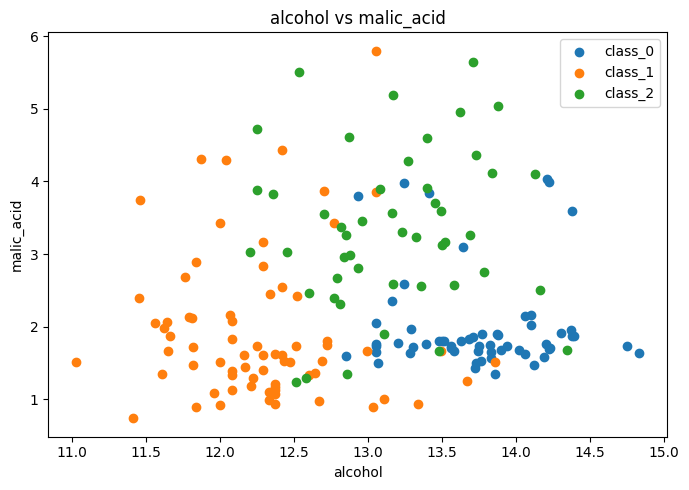

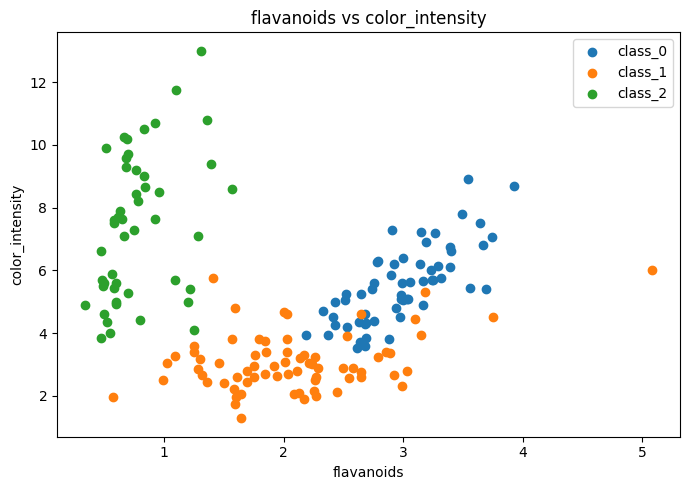

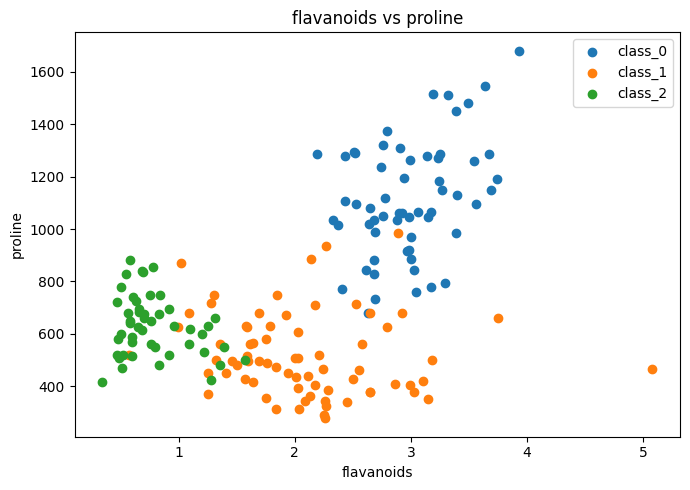

In [4]:
def plot_pair(feature1, feature2):

    plt.figure(figsize=(7, 5))

    for class_value in range(3):
        plt.scatter(
            X[y == class_value, feature1],
            X[y == class_value, feature2],
            label=wine.target_names[class_value]
        )

    plt.xlabel(wine.feature_names[feature1])
    plt.ylabel(wine.feature_names[feature2])

    plt.title(
        wine.feature_names[feature1]
        + " vs "
        + wine.feature_names[feature2]
    )

    plt.legend()
    plt.tight_layout()
    plt.show()


plot_pair(0, 1)
plot_pair(6, 9)
plot_pair(6, 12)

### Observation

Among the selected pairs, **Flavanoids vs Proline** provides a strong visual separation of the three classes. The final choice should be based on the actual plots produced above.

## 5. Standardize All 13 Features

In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (178, 13)


## 6. PCA

In [6]:
pca = PCA(n_components=2)

pca_result = pca.fit_transform(X_scaled)

print("PCA result shape:", pca_result.shape)

print("PCA explained variance ratio:")
print(pca.explained_variance_ratio_)

print(
    "Total variance explained by 2 components:",
    pca.explained_variance_ratio_.sum()
)

PCA result shape: (178, 2)
PCA explained variance ratio:
[0.36198848 0.1920749 ]
Total variance explained by 2 components: 0.5540633835693526


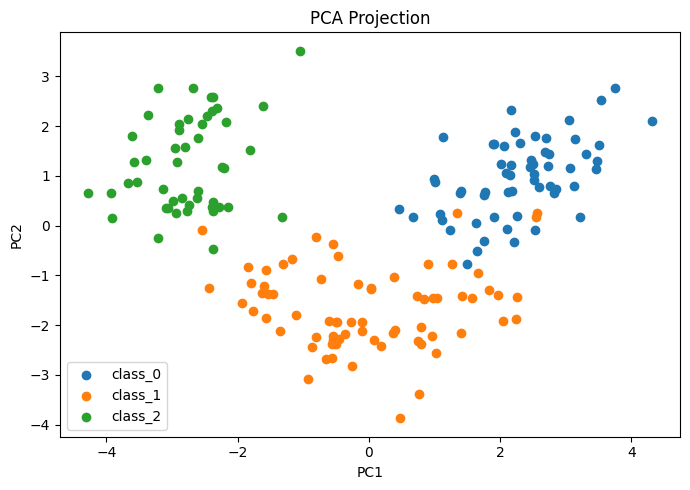

In [7]:
plt.figure(figsize=(7, 5))

for class_value in range(3):
    plt.scatter(
        pca_result[y == class_value, 0],
        pca_result[y == class_value, 1],
        label=wine.target_names[class_value]
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Projection")
plt.legend()
plt.tight_layout()
plt.show()

## 7. t-SNE

In [8]:
tsne = TSNE(
    n_components=2,
    random_state=42
)

tsne_result = tsne.fit_transform(X_scaled)

print("t-SNE result shape:", tsne_result.shape)

t-SNE result shape: (178, 2)


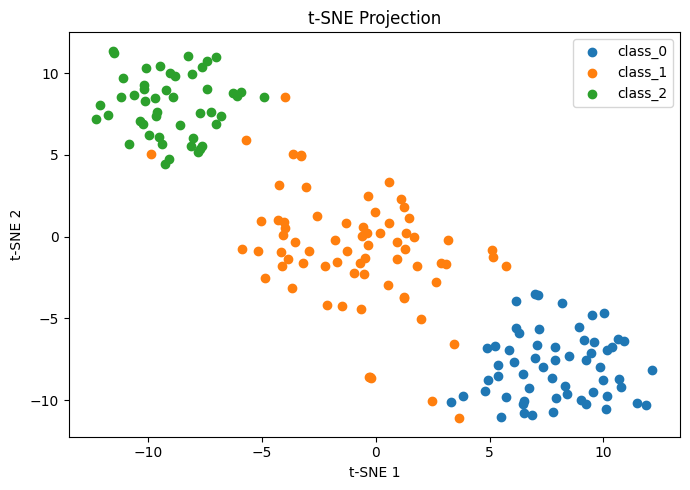

In [9]:
plt.figure(figsize=(7, 5))

for class_value in range(3):
    plt.scatter(
        tsne_result[y == class_value, 0],
        tsne_result[y == class_value, 1],
        label=wine.target_names[class_value]
    )

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("t-SNE Projection")
plt.legend()
plt.tight_layout()
plt.show()

## 8. UMAP

In [10]:
umap_model = umap.UMAP(
    n_components=2,
    random_state=42
)

umap_result = umap_model.fit_transform(X_scaled)

print("UMAP result shape:", umap_result.shape)

c:\Users\dawar\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP result shape: (178, 2)


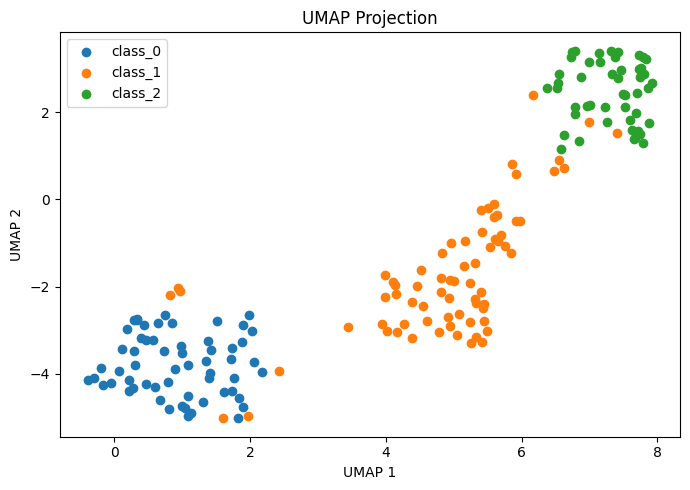

In [11]:
plt.figure(figsize=(7, 5))

for class_value in range(3):
    plt.scatter(
        umap_result[y == class_value, 0],
        umap_result[y == class_value, 1],
        label=wine.target_names[class_value]
    )

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP Projection")
plt.legend()
plt.tight_layout()
plt.show()

## 9. PCA vs t-SNE vs UMAP

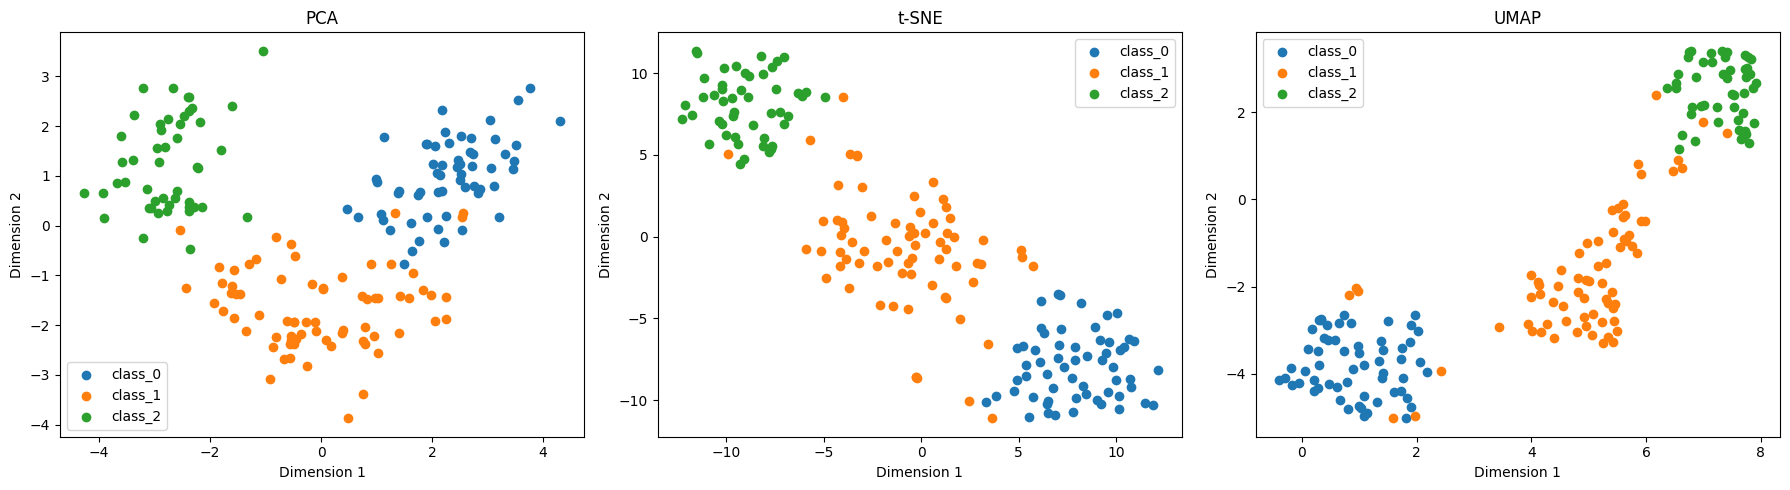

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

results = [
    ("PCA", pca_result),
    ("t-SNE", tsne_result),
    ("UMAP", umap_result)
]

for ax, (title, result) in zip(axes, results):

    for class_value in range(3):
        ax.scatter(
            result[y == class_value, 0],
            result[y == class_value, 1],
            label=wine.target_names[class_value]
        )

    ax.set_title(title)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")
    ax.legend()

plt.tight_layout()
plt.show()

### Comparison

- **PCA:** A linear method that preserves as much overall variance as possible.
- **t-SNE:** A nonlinear method that focuses strongly on local relationships and cluster structure.
- **UMAP:** A nonlinear method that preserves local structure while also maintaining useful broader structure.

The plots can be compared by looking at how clearly the three wine classes form separate groups.

# Output-Driven Problem Solving

The dataset generation below is kept unchanged as required by the lab manual.

The original reduction/plotting code needs two corrections:

1. The dataset has only 20 observations, so `perplexity=30` is too large. We use `perplexity=5`.
2. The generated `labels` must be added to the plotting DataFrame and used with `hue='Group'` so Group A and Group B are displayed separately.

In [13]:
import seaborn as sns

# --- DATASET GENERATION (Do not change) ---
np.random.seed(42)

data = np.random.randn(20, 4)

data[10:, :] += 3.5

labels = ['Group A'] * 10 + ['Group B'] * 10

df_output = pd.DataFrame(
    data,
    columns=['F1', 'F2', 'F3', 'F4']
)

X_scaled_output = df_output.values

In [14]:
# PCA

pca_res = PCA(
    n_components=2
).fit_transform(X_scaled_output)


# t-SNE

tsne_res = TSNE(
    n_components=2,
    perplexity=5,
    random_state=42
).fit_transform(X_scaled_output)


# UMAP

umap_res = umap.UMAP(
    n_components=2,
    n_neighbors=5,
    random_state=42
).fit_transform(X_scaled_output)

c:\Users\dawar\AppData\Local\Programs\Python\Python314\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


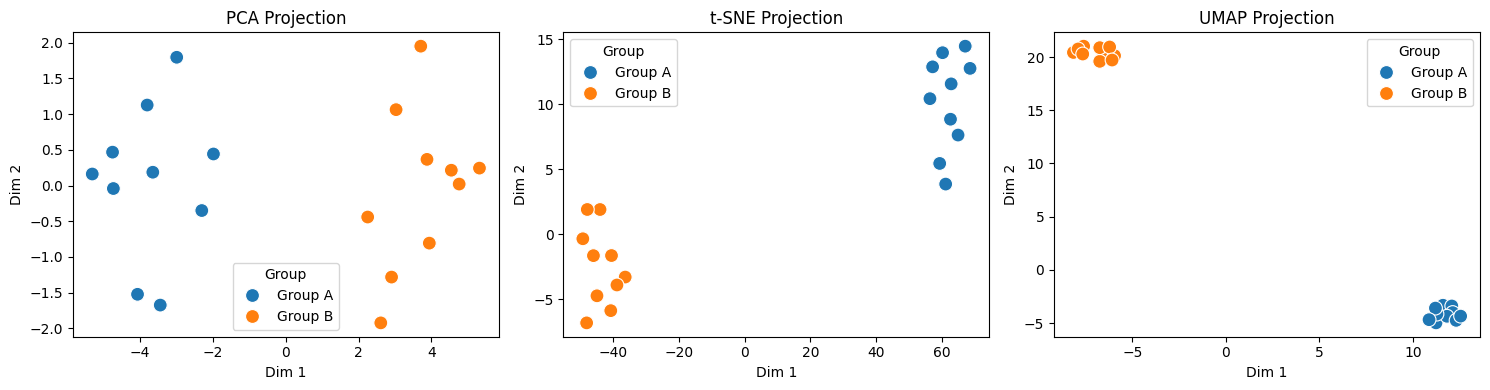

In [15]:
fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

results = [
    ('PCA', pca_res),
    ('t-SNE', tsne_res),
    ('UMAP', umap_res)
]

for ax, (title, res_data) in zip(axes, results):

    plot_df = pd.DataFrame(
        res_data,
        columns=['Dim 1', 'Dim 2']
    )

    plot_df['Group'] = labels

    sns.scatterplot(
        data=plot_df,
        x='Dim 1',
        y='Dim 2',
        hue='Group',
        ax=ax,
        s=100
    )

    ax.set_title(f"{title} Projection")

plt.tight_layout()
plt.show()

## Final Observation

PCA, t-SNE, and UMAP all reduce the data to two dimensions, but they emphasize different aspects of the dataset. PCA focuses on overall variance, while t-SNE and UMAP are nonlinear methods that can make group structure easier to visualize. In the output-driven problem, the corrected t-SNE perplexity allows the method to work with the 20 observations, and the group labels make the two generated groups visible in the plots.